# Gráficos de flujo T - Track


los grafico con python porque no se por qué los archivos eps no se actualizaron con la nueva informacion, y solo tengo los archivos .out

In [1]:
import re
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from matplotlib.colors import LogNorm

In [2]:
def leer_ttrack_2d(archivo):

    archivo = Path(archivo)

    texto = archivo.read_text(
        encoding="utf-8",
        errors="ignore"
    )

    numero = (
        r"[-+]?(?:\d+(?:\.\d*)?|\.\d+)"
        r"(?:[EeDd][-+]?\d+)?"
    )

    def extraer(patron, tipo=float):

        match = re.search(
            patron,
            texto,
            flags=re.MULTILINE | re.IGNORECASE
        )

        if not match:
            raise ValueError(
                f"No se encontró: {patron}"
            )

        valor = match.group(1).replace("D", "E")

        return tipo(valor)

    match_plano = re.search(
        r"^\s*#?\s*axis\s*=\s*(xy|xz|yz)\b",
        texto,
        flags=re.MULTILINE | re.IGNORECASE
    )

    if not match_plano:
        raise ValueError(
            "No se encontró axis = xy, xz o yz."
        )

    plano = match_plano.group(1).lower()

    match_pagina = re.search(
        r"^\s*#?\s*newpage:\s*$",
        texto,
        flags=re.MULTILINE | re.IGNORECASE
    )

    inicio_pagina = (
        match_pagina.end()
        if match_pagina
        else 0
    )

    pagina = texto[inicio_pagina:]

    match_hc = re.search(
        r"^\s*hc:.*$",
        pagina,
        flags=re.MULTILINE | re.IGNORECASE
    )

    if not match_hc:
        raise ValueError(
            "No se encontró la línea hc de la matriz."
        )

    encabezado = pagina[:match_hc.start()]

    match_eje_horizontal = re.search(
        r"^\s*x:\s*([xyz])\s*\[cm\]",
        encabezado,
        flags=re.MULTILINE | re.IGNORECASE
    )

    match_eje_vertical = re.search(
        r"^\s*y:\s*([xyz])\s*\[cm\]",
        encabezado,
        flags=re.MULTILINE | re.IGNORECASE
    )

    if (
        not match_eje_horizontal
        or not match_eje_vertical
    ):
        raise ValueError(
            "No se pudieron identificar "
            "los ejes del gráfico."
        )

    eje_horizontal = (
        match_eje_horizontal
        .group(1)
        .lower()
    )

    eje_vertical = (
        match_eje_vertical
        .group(1)
        .lower()
    )

    def extraer_n(eje):

        patron = (
            rf"^\s*#?\s*n{eje}"
            rf"\s*=\s*(\d+)"
        )

        match = re.search(
            patron,
            texto,
            flags=re.MULTILINE | re.IGNORECASE
        )

        if not match:
            raise ValueError(
                f"No se encontró n{eje} "
                f"en {archivo.name}"
            )

        return int(match.group(1))

    n_horizontal = extraer_n(
        eje_horizontal
    )

    n_vertical = extraer_n(
        eje_vertical
    )

    match_rango_horizontal = re.search(
        rf"p:\s*xmin\(\s*({numero})\s*\)"
        rf"\s*xmax\(\s*({numero})\s*\)",
        encabezado,
        flags=re.IGNORECASE
    )

    match_rango_vertical = re.search(
        rf"p:\s*ymin\(\s*({numero})\s*\)"
        rf"\s*ymax\(\s*({numero})\s*\)",
        encabezado,
        flags=re.IGNORECASE
    )

    if match_rango_horizontal:

        minimo_horizontal = float(
            match_rango_horizontal
            .group(1)
            .replace("D", "E")
        )

        maximo_horizontal = float(
            match_rango_horizontal
            .group(2)
            .replace("D", "E")
        )

    else:

        minimo_horizontal = extraer(
            rf"^\s*#?\s*"
            rf"{eje_horizontal}min"
            rf"\s*=\s*({numero})"
        )

        maximo_horizontal = extraer(
            rf"^\s*#?\s*"
            rf"{eje_horizontal}max"
            rf"\s*=\s*({numero})"
        )

    if match_rango_vertical:

        minimo_vertical = float(
            match_rango_vertical
            .group(1)
            .replace("D", "E")
        )

        maximo_vertical = float(
            match_rango_vertical
            .group(2)
            .replace("D", "E")
        )

    else:

        minimo_vertical = extraer(
            rf"^\s*#?\s*"
            rf"{eje_vertical}min"
            rf"\s*=\s*({numero})"
        )

        maximo_vertical = extraer(
            rf"^\s*#?\s*"
            rf"{eje_vertical}max"
            rf"\s*=\s*({numero})"
        )

    match_limites = re.search(
        rf"set:\s*c3\[\s*({numero})\s*\]"
        rf"\s*c4\[\s*({numero})\s*\]",
        encabezado,
        flags=re.IGNORECASE
    )

    if match_limites:

        cmin = float(
            match_limites
            .group(1)
            .replace("D", "E")
        )

        cmax = float(
            match_limites
            .group(2)
            .replace("D", "E")
        )

    else:

        cmin = None
        cmax = None

    match_particula = re.search(
        r"^\s*#?\s*part\s*=\s*([^\n#]+)",
        texto,
        flags=re.MULTILINE | re.IGNORECASE
    )

    particula = (
        match_particula.group(1).strip()
        if match_particula
        else archivo.stem
    )

    inicio_datos = (
        inicio_pagina
        + match_hc.end()
    )

    match_fin = re.search(
        r"^\s*#\s*gshow\s*$"
        r"|^\s*newpage:\s*$"
        r"|^\s*#\s*newpage:\s*$"
        r"|^\s*#\s*Information for Restart",
        texto[inicio_datos:],
        flags=re.MULTILINE | re.IGNORECASE
    )

    if match_fin:

        fin_datos = (
            inicio_datos
            + match_fin.start()
        )

    else:

        fin_datos = len(texto)

    bloque_datos = texto[
        inicio_datos:fin_datos
    ]

    numeros = re.findall(
        numero,
        bloque_datos
    )

    valores = np.array([
        float(
            valor.replace("D", "E")
        )
        for valor in numeros
    ])

    cantidad = (
        n_horizontal
        * n_vertical
    )

    if valores.size < cantidad:

        raise ValueError(
            f"Se esperaban {cantidad} "
            f"valores, pero se encontraron "
            f"{valores.size}."
        )

    flujo = valores[
        :cantidad
    ].reshape(
        n_vertical,
        n_horizontal
    )

    positivos = flujo[
        flujo > 0
    ]

    if positivos.size == 0:
        raise ValueError(
            "El archivo no contiene "
            "valores positivos."
        )

    if cmin is None or cmin <= 0:
        cmin = positivos.min()

    if cmax is None or cmax <= 0:
        cmax = positivos.max()

    if cmax <= cmin:
        cmin = positivos.min()
        cmax = positivos.max()

    geometria = []

    match_gshow = re.search(
        r"^\s*#\s*gshow\s*$",
        texto[inicio_datos:],
        flags=re.MULTILINE | re.IGNORECASE
    )

    if match_gshow:

        inicio_gshow = (
            inicio_datos
            + match_gshow.end()
        )

        bloque_gshow = texto[
            inicio_gshow:
        ]

        match_colorbar = re.search(
            r"^\s*z:\s*xorg",
            bloque_gshow,
            flags=re.MULTILINE | re.IGNORECASE
        )

        if match_colorbar:

            bloque_gshow = (
                bloque_gshow[
                    :match_colorbar.start()
                ]
            )

        lineas = (
            bloque_gshow
            .splitlines()
        )

        i = 0

        while i < len(lineas):

            if (
                lineas[i]
                .strip()
                .lower()
                == "clip:"
            ):

                puntos = []
                i += 1

                while i < len(lineas):

                    partes = (
                        lineas[i]
                        .split()
                    )

                    if len(partes) != 2:
                        break

                    try:

                        coordenada_1 = float(
                            partes[0]
                            .replace("D", "E")
                        )

                        coordenada_2 = float(
                            partes[1]
                            .replace("D", "E")
                        )

                        puntos.append(
                            (
                                coordenada_1,
                                coordenada_2
                            )
                        )

                        i += 1

                    except ValueError:
                        break

                if len(puntos) >= 2:

                    geometria.append(
                        np.array(puntos)
                    )

            else:
                i += 1

    return {
        "archivo": archivo,
        "flujo": flujo,
        "plano": plano,
        "eje_horizontal": eje_horizontal,
        "eje_vertical": eje_vertical,
        "minimo_horizontal": minimo_horizontal,
        "maximo_horizontal": maximo_horizontal,
        "minimo_vertical": minimo_vertical,
        "maximo_vertical": maximo_vertical,
        "cmin": cmin,
        "cmax": cmax,
        "particula": particula,
        "geometria": geometria
    }


def graficar_ttrack_2d(
    archivo,
    mostrar_geometria=True,
    mostrar_bineado=False,
    tamano=None,
    barra="abajo"
):

    if isinstance(archivo, dict):
        datos = archivo
    else:
        datos = leer_ttrack_2d(
            archivo
        )

    es_error = (
        datos["archivo"]
        .stem
        .lower()
        .endswith("_err")
    )

    valores = np.ma.masked_less_equal(
        datos["flujo"],
        0
    )

    ancho_datos = (
        datos["maximo_horizontal"]
        - datos["minimo_horizontal"]
    )

    alto_datos = (
        datos["maximo_vertical"]
        - datos["minimo_vertical"]
    )

    proporcion = (
        ancho_datos
        / alto_datos
    )

    if tamano is None:

        if proporcion >= 2:
            tamano = (15, 5)

        elif proporcion <= 0.5:
            tamano = (6, 10)

        else:
            tamano = (8, 7)

    cmap = (
        plt.colormaps["jet"]
        .resampled(100)
        .copy()
    )

    cmap.set_bad("white")
    cmap.set_under("white")

    fig, ax = plt.subplots(
        figsize=tamano,
        constrained_layout=True
    )

    imagen = ax.imshow(
        valores,
        origin="upper",
        extent=[
            datos["minimo_horizontal"],
            datos["maximo_horizontal"],
            datos["minimo_vertical"],
            datos["maximo_vertical"]
        ],
        aspect="equal",
        interpolation="nearest",
        cmap=cmap,
        norm=LogNorm(
            vmin=datos["cmin"],
            vmax=datos["cmax"]
        )
    )

    if mostrar_geometria:

        for curva in datos["geometria"]:

            ax.plot(
                curva[:, 0],
                curva[:, 1],
                color="black",
                linewidth=0.7
            )

    if mostrar_bineado:

        n_vertical, n_horizontal = (
            datos["flujo"].shape
        )

        texto_bineado = (
            f"n{datos['eje_horizontal']} "
            f"= {n_horizontal}\n"
            f"n{datos['eje_vertical']} "
            f"= {n_vertical}"
        )

        ax.text(
            0.02,
            0.97,
            texto_bineado,
            transform=ax.transAxes,
            horizontalalignment="left",
            verticalalignment="top",
            bbox={
                "facecolor": "white",
                "edgecolor": "black",
                "alpha": 0.8,
                "boxstyle": "round,pad=0.3"
            }
        )

    if barra == "abajo":

        colorbar = fig.colorbar(
            imagen,
            ax=ax,
            orientation="horizontal",
            pad=0.16,
            fraction=0.10,
            aspect=45
        )

    elif barra == "derecha":

        colorbar = fig.colorbar(
            imagen,
            ax=ax,
            orientation="vertical",
            pad=0.03,
            fraction=0.05,
            aspect=30
        )

    else:

        raise ValueError(
            'barra debe ser '
            '"abajo" o "derecha".'
        )

    if es_error:

        colorbar.set_label(
            "Error relativo"
        )

        tipo = (
            "Error relativo del T-Track"
        )

    else:

        colorbar.set_label(
            "Flujo [1/cm²/source]"
        )

        tipo = "T-Track"

    ax.set_xlabel(
        f"{datos['eje_horizontal']} [cm]"
    )

    ax.set_ylabel(
        f"{datos['eje_vertical']} [cm]"
    )

    ax.set_title(
        f"{tipo} de "
        f"{datos['particula']} "
        f"en el plano "
        f"{datos['plano']}\n"
        f"{datos['archivo'].name}",
        pad=10
    )

    ax.set_xlim(
        datos["minimo_horizontal"],
        datos["maximo_horizontal"]
    )

    ax.set_ylim(
        datos["minimo_vertical"],
        datos["maximo_vertical"]
    )

    plt.show()

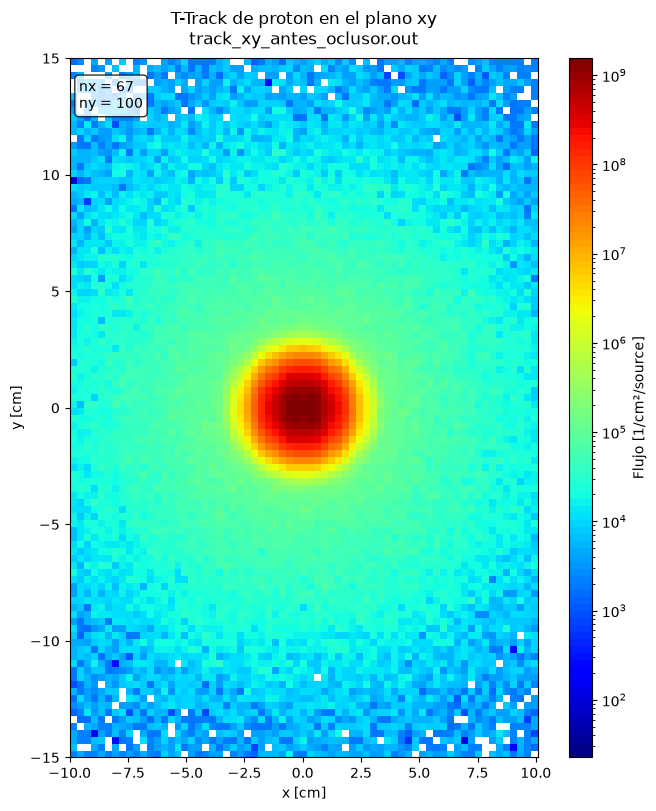

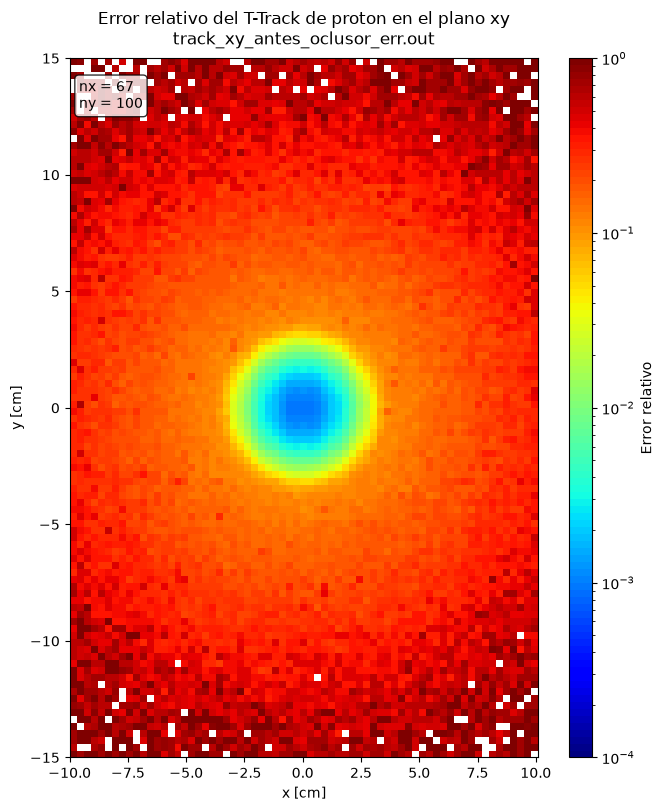

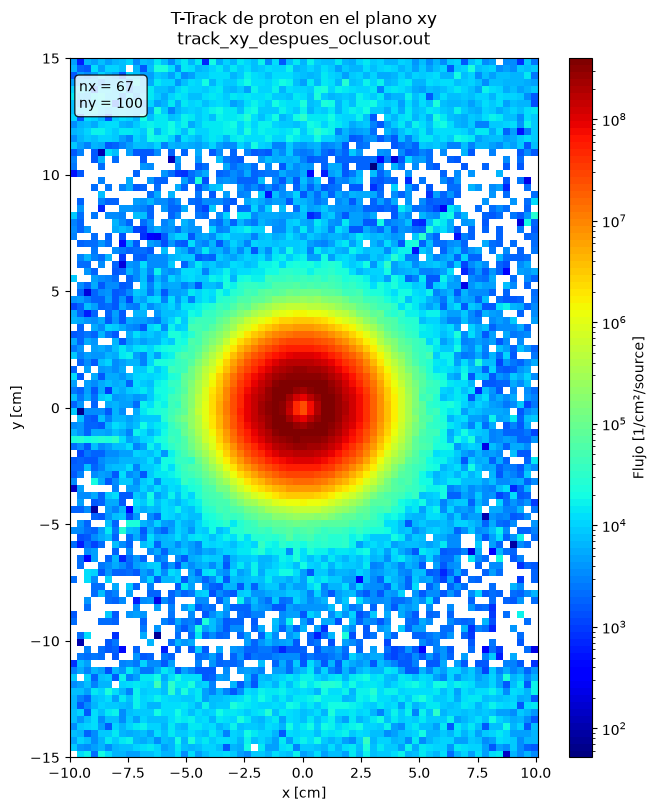

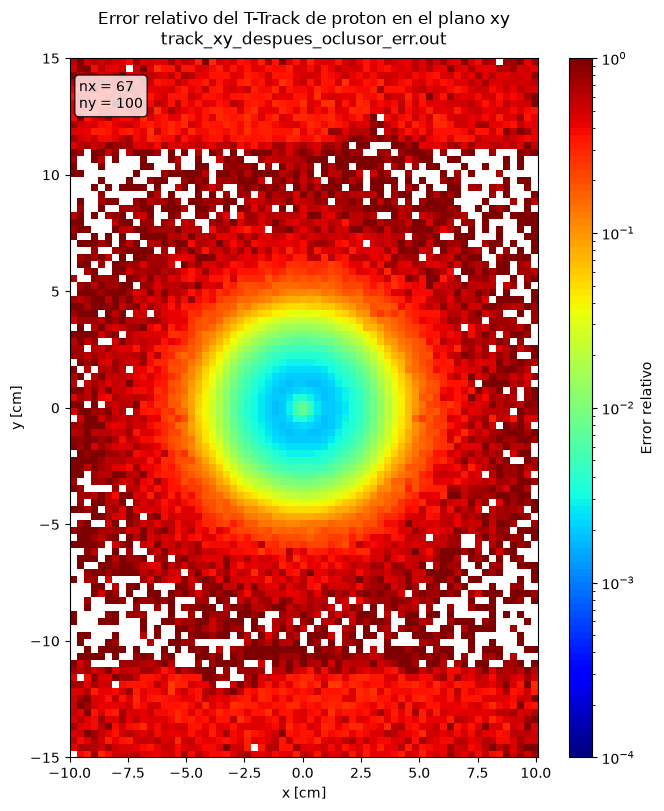

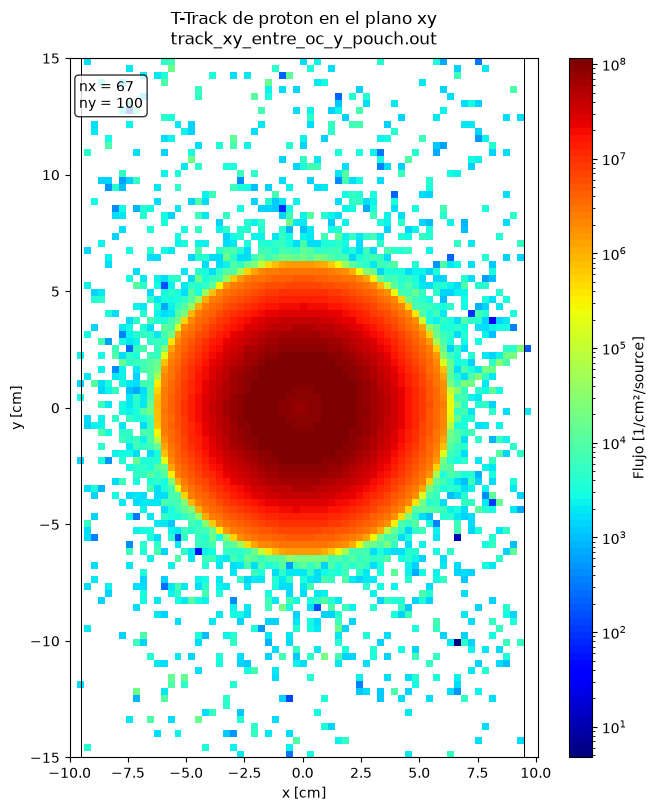

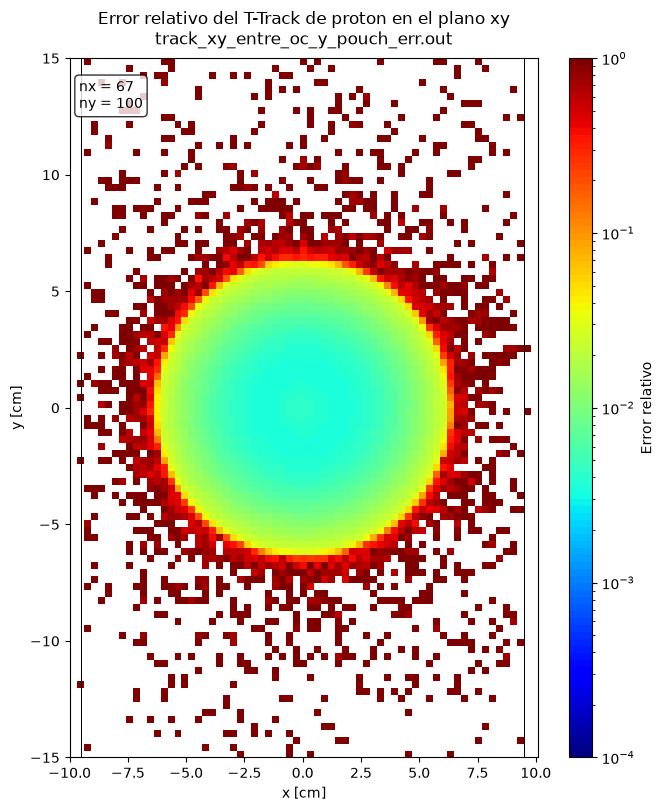

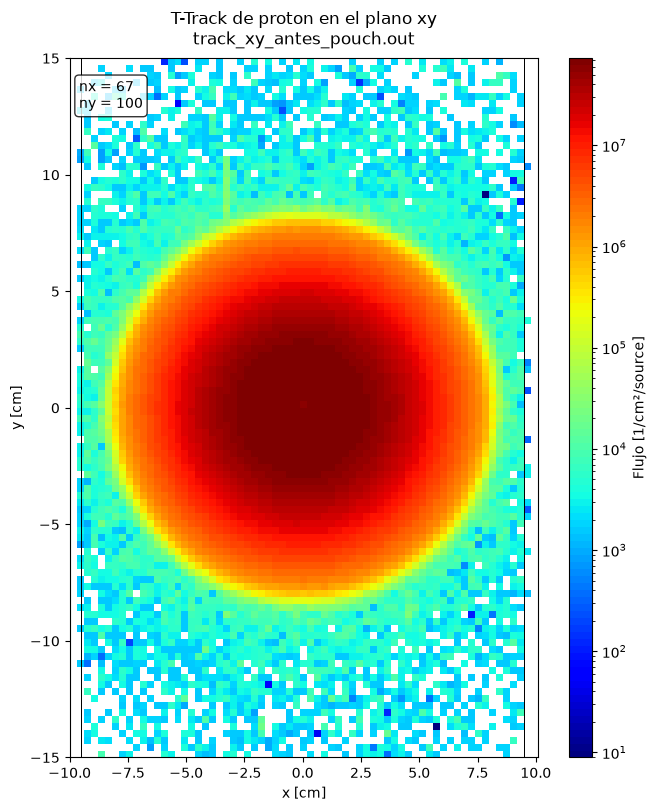

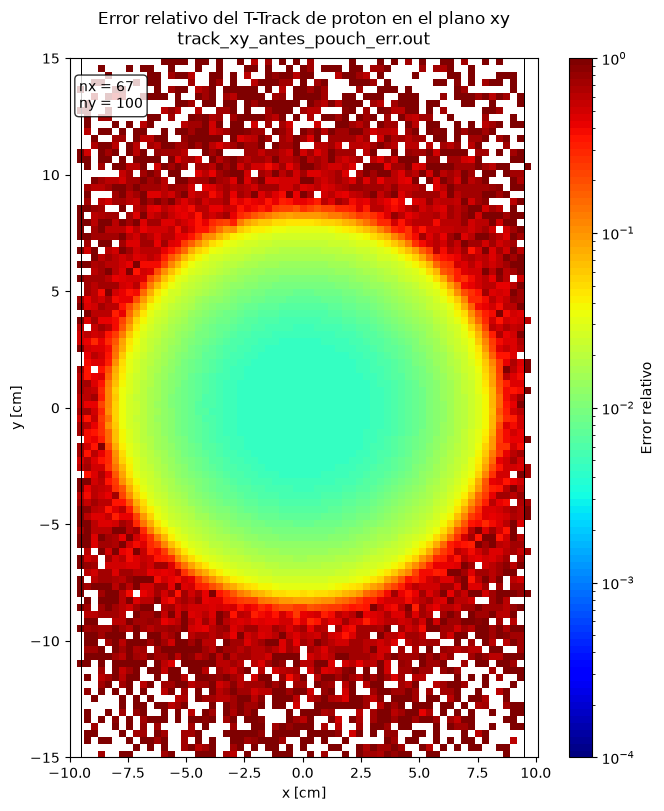

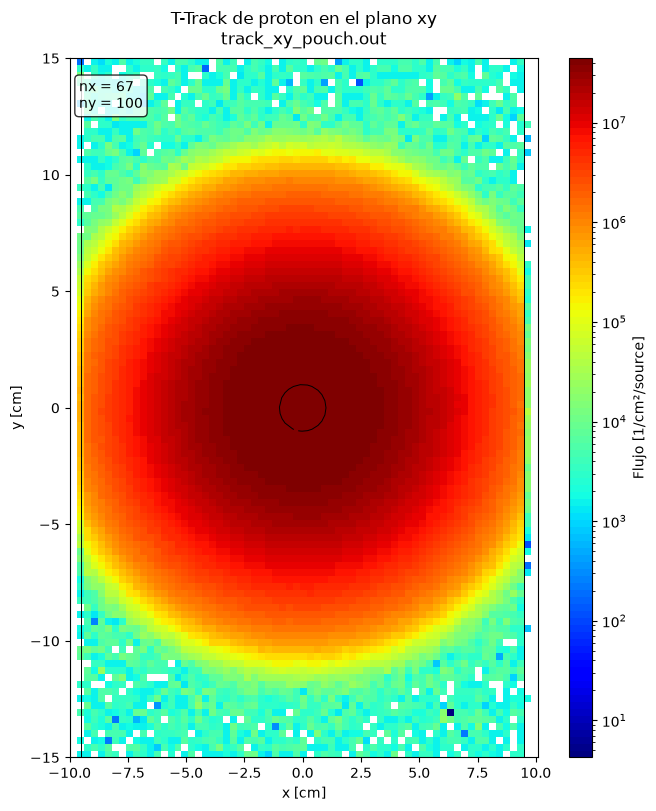

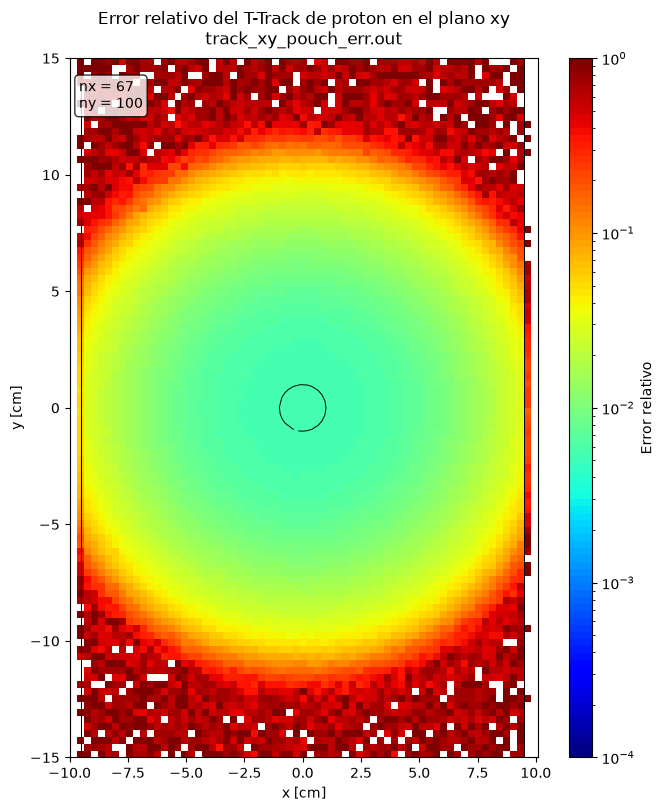

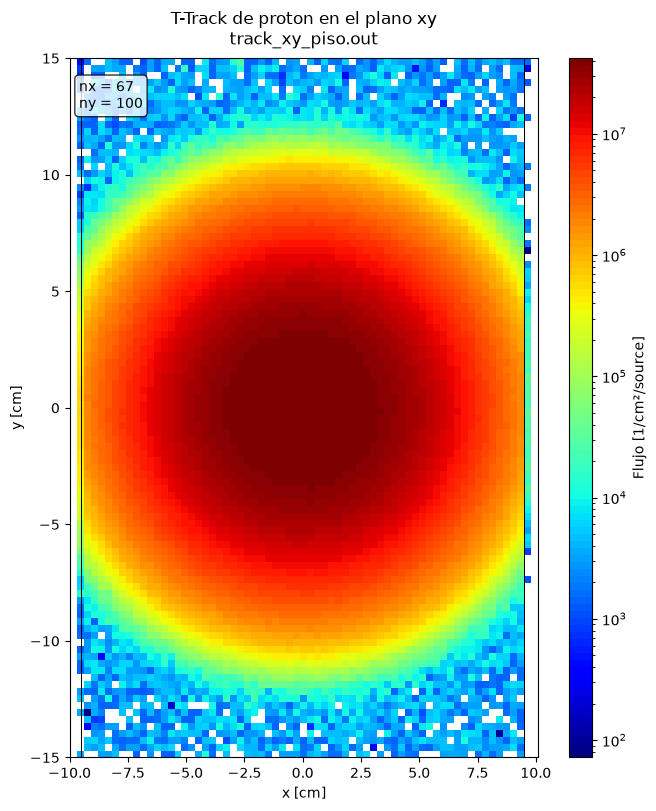

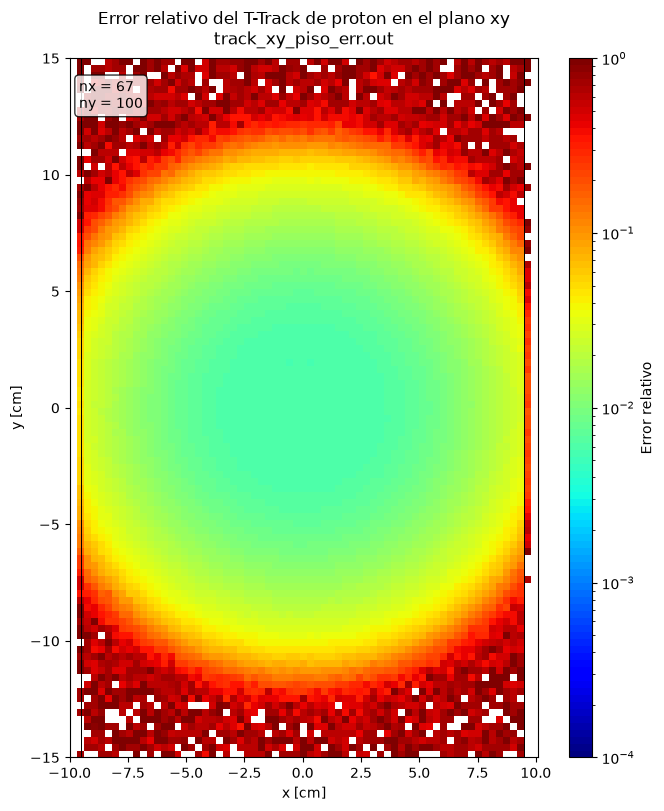

In [6]:
ruta = Path("../out")

track_xy_antes_oclusor = leer_ttrack_2d(
    ruta / "track_xy_antes_oclusor.out"
)
track_xy_antes_oclusor_error = leer_ttrack_2d(
    ruta / "track_xy_antes_oclusor_err.out"
)
track_xy_despues_oclusor = leer_ttrack_2d(
    ruta / "track_xy_despues_oclusor.out"
)
track_xy_despues_oclusor_error = leer_ttrack_2d(
    ruta / "track_xy_despues_oclusor_err.out"
)
track_xy_entre_oc_y_pouch = leer_ttrack_2d(
    ruta / "track_xy_entre_oc_y_pouch.out"
)
track_xy_entre_oc_y_pouch_error = leer_ttrack_2d(
    ruta / "track_xy_entre_oc_y_pouch_err.out"
)
track_xy_antes_pouch = leer_ttrack_2d(
    ruta / "track_xy_antes_pouch.out"
)
track_xy_antes_pouch_error = leer_ttrack_2d(
    ruta / "track_xy_antes_pouch_err.out"
)
track_xy_pouch = leer_ttrack_2d(
    ruta / "track_xy_pouch.out"
)
track_xy_pouch_error = leer_ttrack_2d(
    ruta / "track_xy_pouch_err.out"
)
track_xy_piso = leer_ttrack_2d(
    ruta / "track_xy_piso.out"
)
track_xy_piso_error = leer_ttrack_2d(
    ruta / "track_xy_piso_err.out"
)



graficar_ttrack_2d(
    track_xy_antes_oclusor,
    tamano=(7, 8),
    mostrar_bineado=True,
    barra="derecha"
)

graficar_ttrack_2d(
    track_xy_antes_oclusor_error,
    tamano=(7, 8),
    mostrar_bineado=True,
    barra="derecha"
)

graficar_ttrack_2d(
    track_xy_despues_oclusor,
    tamano=(7, 8),
    mostrar_bineado=True,
    barra="derecha"
)

graficar_ttrack_2d(
    track_xy_despues_oclusor_error,
    tamano=(7, 8),
    mostrar_bineado=True,
    barra="derecha"
)

graficar_ttrack_2d(
    track_xy_entre_oc_y_pouch,
    tamano=(7, 8),
    mostrar_bineado=True,
    barra="derecha"
)

graficar_ttrack_2d(
    track_xy_entre_oc_y_pouch_error,
    tamano=(7, 8),
    mostrar_bineado=True,
    barra="derecha"
)

graficar_ttrack_2d(
    track_xy_antes_pouch,
    tamano=(7, 8),
    mostrar_bineado=True,
    barra="derecha"
)

graficar_ttrack_2d(
    track_xy_antes_pouch_error,
    tamano=(7, 8),
    mostrar_bineado=True,
    barra="derecha"
)

graficar_ttrack_2d(
    track_xy_pouch,
    tamano=(7, 8),
    mostrar_bineado=True,
    barra="derecha"
)

graficar_ttrack_2d(
    track_xy_pouch_error,
    tamano=(7, 8),
    mostrar_bineado=True,
    barra="derecha"
)

graficar_ttrack_2d(
    track_xy_piso,
    tamano=(7, 8),
    mostrar_bineado=True,
    barra="derecha"
)

graficar_ttrack_2d(
    track_xy_piso_error,
    tamano=(7, 8),
    mostrar_bineado=True,
    barra="derecha"
)


RESULTADOS DE LOS 6 T-TRACK

   z [cm]      FWHM X      FWHM Y        R X        R Y    Fluencia max
    33.94       1.842       1.849      0.934      1.000      1.5510e+09
    45.00       3.690       3.792      0.069      0.073      4.0000e+08
    66.80       6.632       6.603      0.693      0.679      1.1520e+08
    80.00       8.261       8.248      0.867      0.857      7.2610e+07
    98.48      10.445      10.460      0.967      0.966      4.4350e+07
   100.96      10.754      10.725      0.972      0.968      4.2090e+07


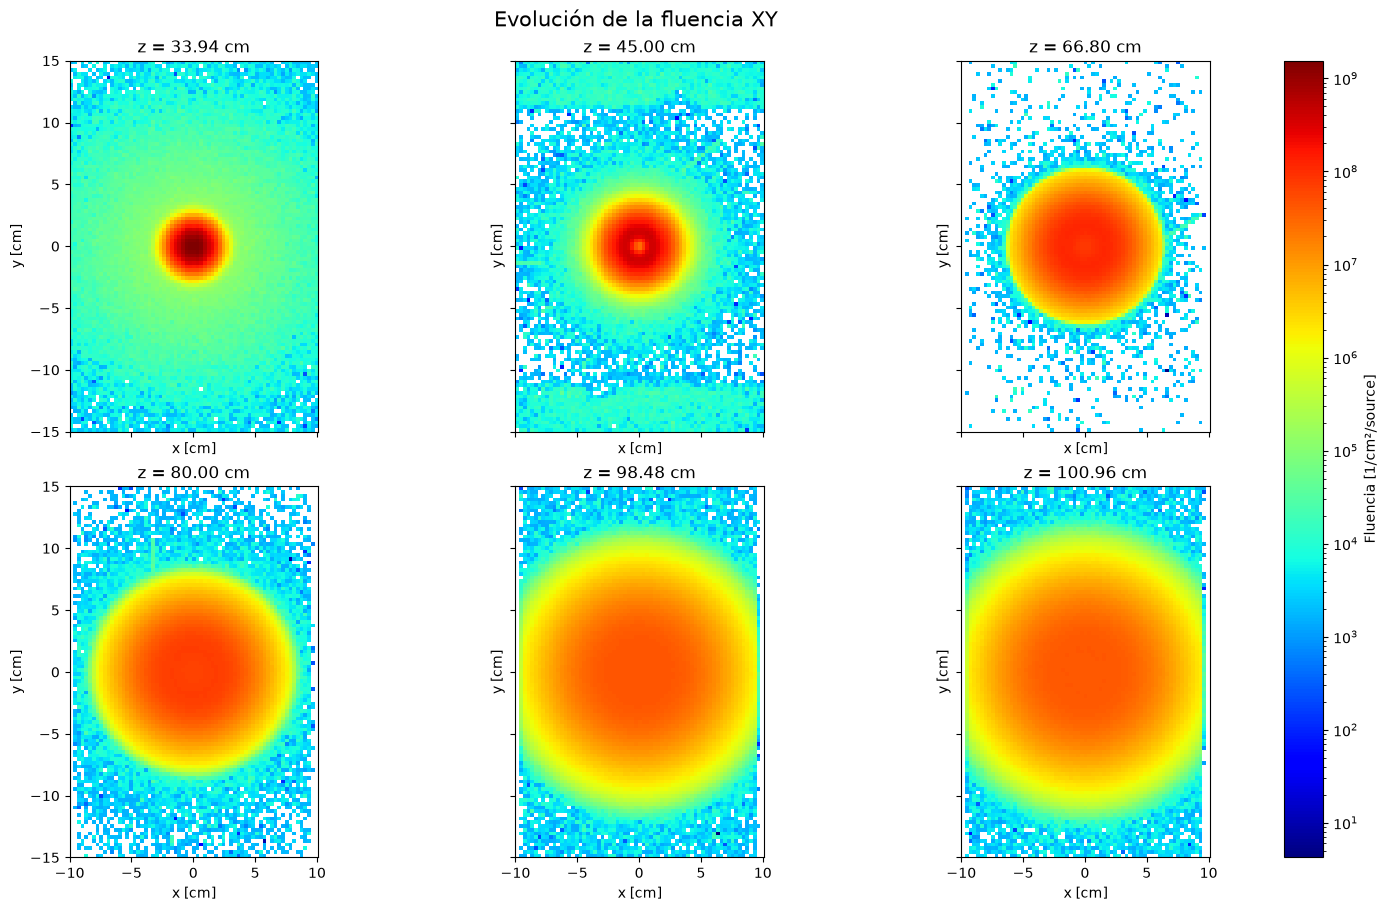

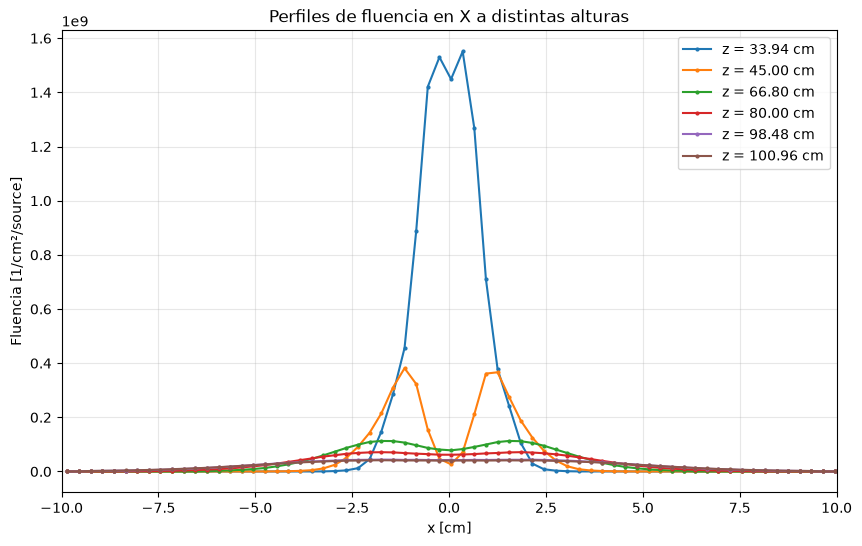

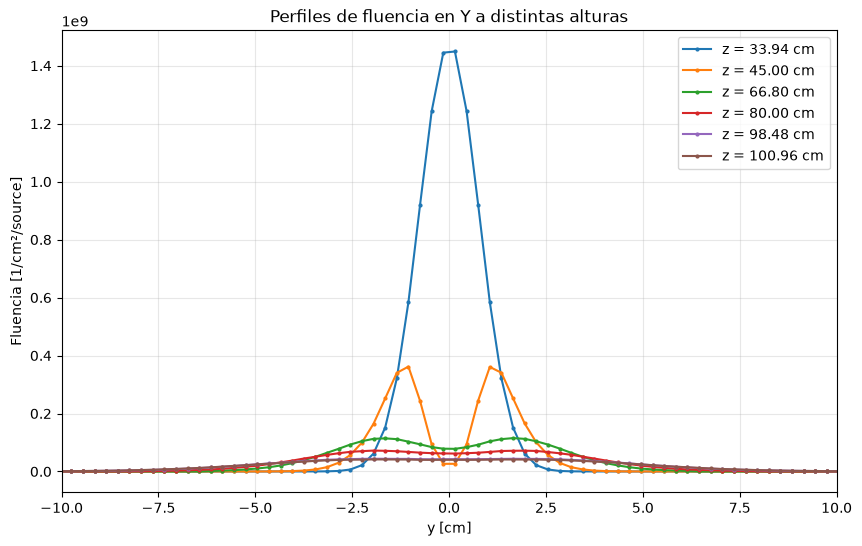

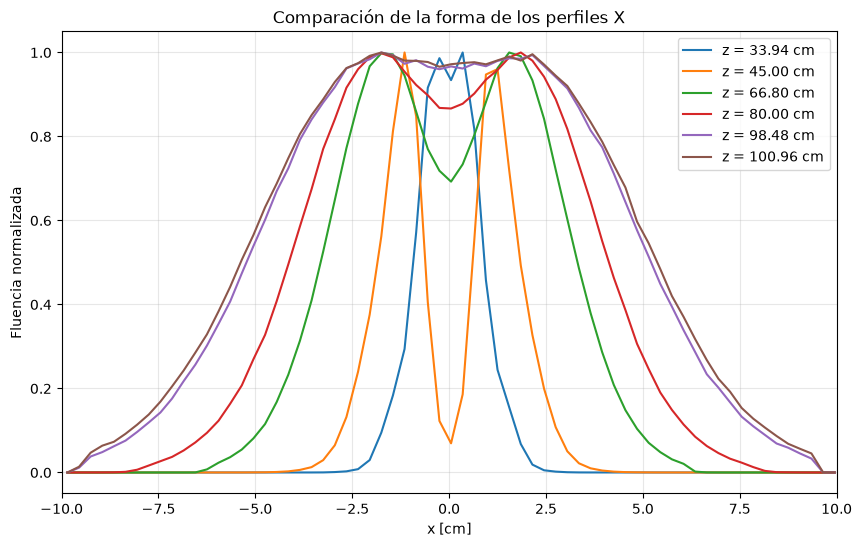

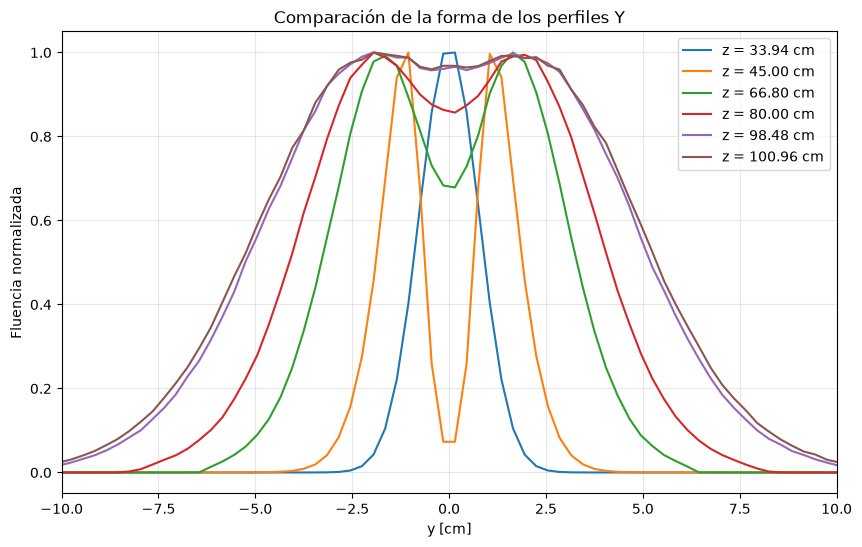

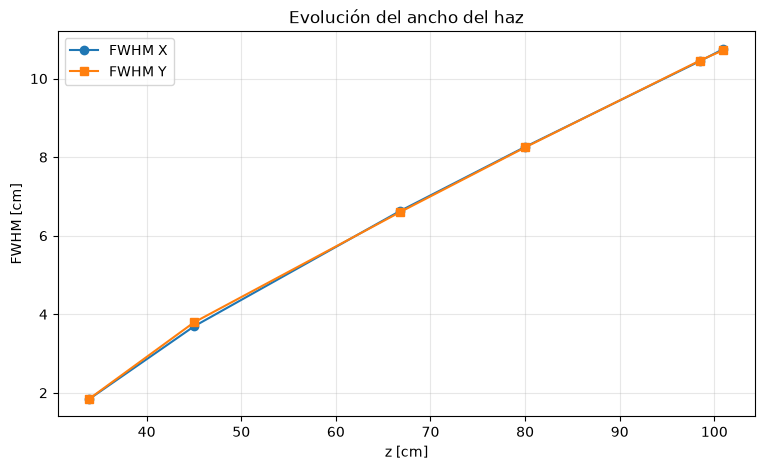

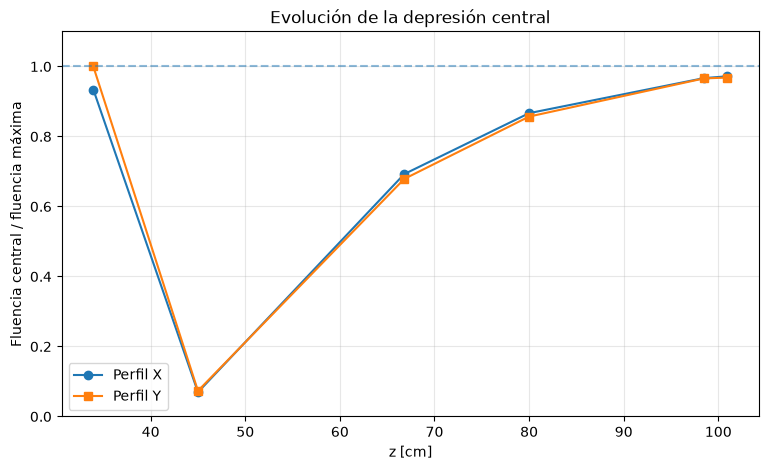

In [7]:

import numpy as np
import matplotlib.pyplot as plt
import re
from pathlib import Path
from matplotlib.colors import LogNorm

carpeta = Path("..") / "out"

archivos = [
    (33.94, "track_xy_antes_oclusor.out"),
    (45.00, "track_xy_despues_oclusor.out"),
    (66.80, "track_xy_entre_oc_y_pouch.out"),
    (80.00, "track_xy_antes_pouch.out"),
    (98.48, "track_xy_pouch.out"),
    (100.96, "track_xy_piso.out"),
]

xmin, xmax, xdel = -10, 10, 0.3
ymin, ymax, ydel = -15, 15, 0.3


def leer_ttrack(filename):
    with open(filename, "r") as f:
        lines = f.readlines()

    nx = ny = None
    inicio = None

    for i, line in enumerate(lines):
        if "nx =" in line and "ny =" in line:
            mx = re.search(r"\bnx\s*=\s*(\d+)", line)
            my = re.search(r"\bny\s*=\s*(\d+)", line)

            if mx and my:
                nx = int(mx.group(1))
                ny = int(my.group(1))

        if line.strip().startswith("hc:") and inicio is None:
            inicio = i + 1

    if nx is None or ny is None:
        raise ValueError(f"No se encontraron nx y ny en {filename}")

    if inicio is None:
        raise ValueError(f"No se encontró 'hc:' en {filename}")

    datos = []

    patron = r"[-+]?(?:\d+(?:\.\d*)?|\.\d+)(?:[EeDd][-+]?\d+)?"

    for line in lines[inicio:]:
        if line.strip().startswith("#"):
            break

        numeros = re.findall(patron, line)

        for numero in numeros:
            datos.append(float(numero.replace("D", "E").replace("d", "e")))

        if len(datos) >= nx * ny:
            break

    datos = np.array(datos[:nx * ny])

    if len(datos) != nx * ny:
        raise ValueError(
            f"{filename}: se esperaban {nx * ny} datos, "
            f"pero se encontraron {len(datos)}."
        )

    flujo = datos.reshape((ny, nx))[::-1, :]

    return flujo, nx, ny


def calcular_fwhm(coordenadas, perfil):
    maximo = np.max(perfil)
    mitad = maximo / 2

    indices = np.where(perfil >= mitad)[0]

    if len(indices) == 0:
        return np.nan, np.nan, np.nan, mitad

    i_izq = indices[0]
    i_der = indices[-1]

    if i_izq == 0 or i_der == len(perfil) - 1:
        return np.nan, np.nan, np.nan, mitad

    x_izq = np.interp(
        mitad,
        perfil[i_izq - 1:i_izq + 1],
        coordenadas[i_izq - 1:i_izq + 1]
    )

    x_der = np.interp(
        mitad,
        perfil[i_der:i_der + 2][::-1],
        coordenadas[i_der:i_der + 2][::-1]
    )

    return x_der - x_izq, x_izq, x_der, mitad


resultados = []

for z, nombre in archivos:
    archivo = carpeta / nombre

    flujo, nx, ny = leer_ttrack(archivo)

    x = xmin + (np.arange(nx) + 0.5) * xdel
    y = ymin + (np.arange(ny) + 0.5) * ydel

    ix_centro = np.argmin(np.abs(x))
    iy_centro = np.argmin(np.abs(y))

    perfil_x = flujo[iy_centro, :]
    perfil_y = flujo[:, ix_centro]

    fwhm_x, x_izq, x_der, mitad_x = calcular_fwhm(x, perfil_x)
    fwhm_y, y_izq, y_der, mitad_y = calcular_fwhm(y, perfil_y)

    iy_max, ix_max = np.unravel_index(np.argmax(flujo), flujo.shape)

    r_x = perfil_x[ix_centro] / np.max(perfil_x)
    r_y = perfil_y[iy_centro] / np.max(perfil_y)

    resultados.append({
        "z": z,
        "archivo": nombre,
        "flujo": flujo,
        "x": x,
        "y": y,
        "perfil_x": perfil_x,
        "perfil_y": perfil_y,
        "fwhm_x": fwhm_x,
        "fwhm_y": fwhm_y,
        "x_max": x[ix_max],
        "y_max": y[iy_max],
        "flujo_max": flujo[iy_max, ix_max],
        "r_x": r_x,
        "r_y": r_y
    })


print("\nRESULTADOS DE LOS 6 T-TRACK\n")

print(
    f"{'z [cm]':>9} "
    f"{'FWHM X':>11} "
    f"{'FWHM Y':>11} "
    f"{'R X':>10} "
    f"{'R Y':>10} "
    f"{'Fluencia max':>15}"
)

for r in resultados:
    print(
        f"{r['z']:9.2f} "
        f"{r['fwhm_x']:11.3f} "
        f"{r['fwhm_y']:11.3f} "
        f"{r['r_x']:10.3f} "
        f"{r['r_y']:10.3f} "
        f"{r['flujo_max']:15.4e}"
    )


fig, axes = plt.subplots(
    2, 3,
    figsize=(15, 9),
    sharex=True,
    sharey=True,
    constrained_layout=True
)

positivos = np.concatenate([
    r["flujo"][r["flujo"] > 0].ravel()
    for r in resultados
])

normalizacion = LogNorm(
    vmin=np.min(positivos),
    vmax=np.max(positivos)
)

for ax, r in zip(axes.flat, resultados):
    imagen = ax.imshow(
        np.ma.masked_less_equal(r["flujo"], 0),
        origin="lower",
        extent=[
            xmin,
            xmin + r["flujo"].shape[1] * xdel,
            ymin,
            ymin + r["flujo"].shape[0] * ydel
        ],
        aspect="equal",
        cmap="jet",
        norm=normalizacion,
        interpolation="nearest"
    )

    ax.set_title(f"z = {r['z']:.2f} cm")
    ax.set_xlabel("x [cm]")
    ax.set_ylabel("y [cm]")

fig.colorbar(
    imagen,
    ax=axes.ravel().tolist(),
    label="Fluencia [1/cm²/source]"
)

fig.suptitle("Evolución de la fluencia XY", fontsize=15)
plt.show()


plt.figure(figsize=(10, 6))

for r in resultados:
    plt.plot(
        r["x"],
        r["perfil_x"],
        marker="o",
        markersize=2,
        label=f"z = {r['z']:.2f} cm"
    )

plt.xlabel("x [cm]")
plt.ylabel("Fluencia [1/cm²/source]")
plt.title("Perfiles de fluencia en X a distintas alturas")
plt.legend()
plt.grid(alpha=0.3)
plt.xlim(-10, 10)
plt.show()


plt.figure(figsize=(10, 6))

for r in resultados:
    plt.plot(
        r["y"],
        r["perfil_y"],
        marker="o",
        markersize=2,
        label=f"z = {r['z']:.2f} cm"
    )

plt.xlabel("y [cm]")
plt.ylabel("Fluencia [1/cm²/source]")
plt.title("Perfiles de fluencia en Y a distintas alturas")
plt.legend()
plt.grid(alpha=0.3)
plt.xlim(-10, 10)
plt.show()


plt.figure(figsize=(10, 6))

for r in resultados:
    perfil_normalizado = r["perfil_x"] / np.max(r["perfil_x"])

    plt.plot(
        r["x"],
        perfil_normalizado,
        label=f"z = {r['z']:.2f} cm"
    )

plt.xlabel("x [cm]")
plt.ylabel("Fluencia normalizada")
plt.title("Comparación de la forma de los perfiles X")
plt.legend()
plt.grid(alpha=0.3)
plt.xlim(-10, 10)
plt.show()


plt.figure(figsize=(10, 6))

for r in resultados:
    perfil_normalizado = r["perfil_y"] / np.max(r["perfil_y"])

    plt.plot(
        r["y"],
        perfil_normalizado,
        label=f"z = {r['z']:.2f} cm"
    )

plt.xlabel("y [cm]")
plt.ylabel("Fluencia normalizada")
plt.title("Comparación de la forma de los perfiles Y")
plt.legend()
plt.grid(alpha=0.3)
plt.xlim(-10, 10)
plt.show()


alturas = np.array([r["z"] for r in resultados])
anchos_x = np.array([r["fwhm_x"] for r in resultados])
anchos_y = np.array([r["fwhm_y"] for r in resultados])

plt.figure(figsize=(9, 5))
plt.plot(alturas, anchos_x, "o-", label="FWHM X")
plt.plot(alturas, anchos_y, "s-", label="FWHM Y")
plt.xlabel("z [cm]")
plt.ylabel("FWHM [cm]")
plt.title("Evolución del ancho del haz")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


r_x = np.array([r["r_x"] for r in resultados])
r_y = np.array([r["r_y"] for r in resultados])

plt.figure(figsize=(9, 5))
plt.plot(alturas, r_x, "o-", label="Perfil X")
plt.plot(alturas, r_y, "s-", label="Perfil Y")
plt.axhline(1, linestyle="--", alpha=0.5)
plt.xlabel("z [cm]")
plt.ylabel("Fluencia central / fluencia máxima")
plt.title("Evolución de la depresión central")
plt.ylim(0, 1.1)
plt.legend()
plt.grid(alpha=0.3)
plt.show()


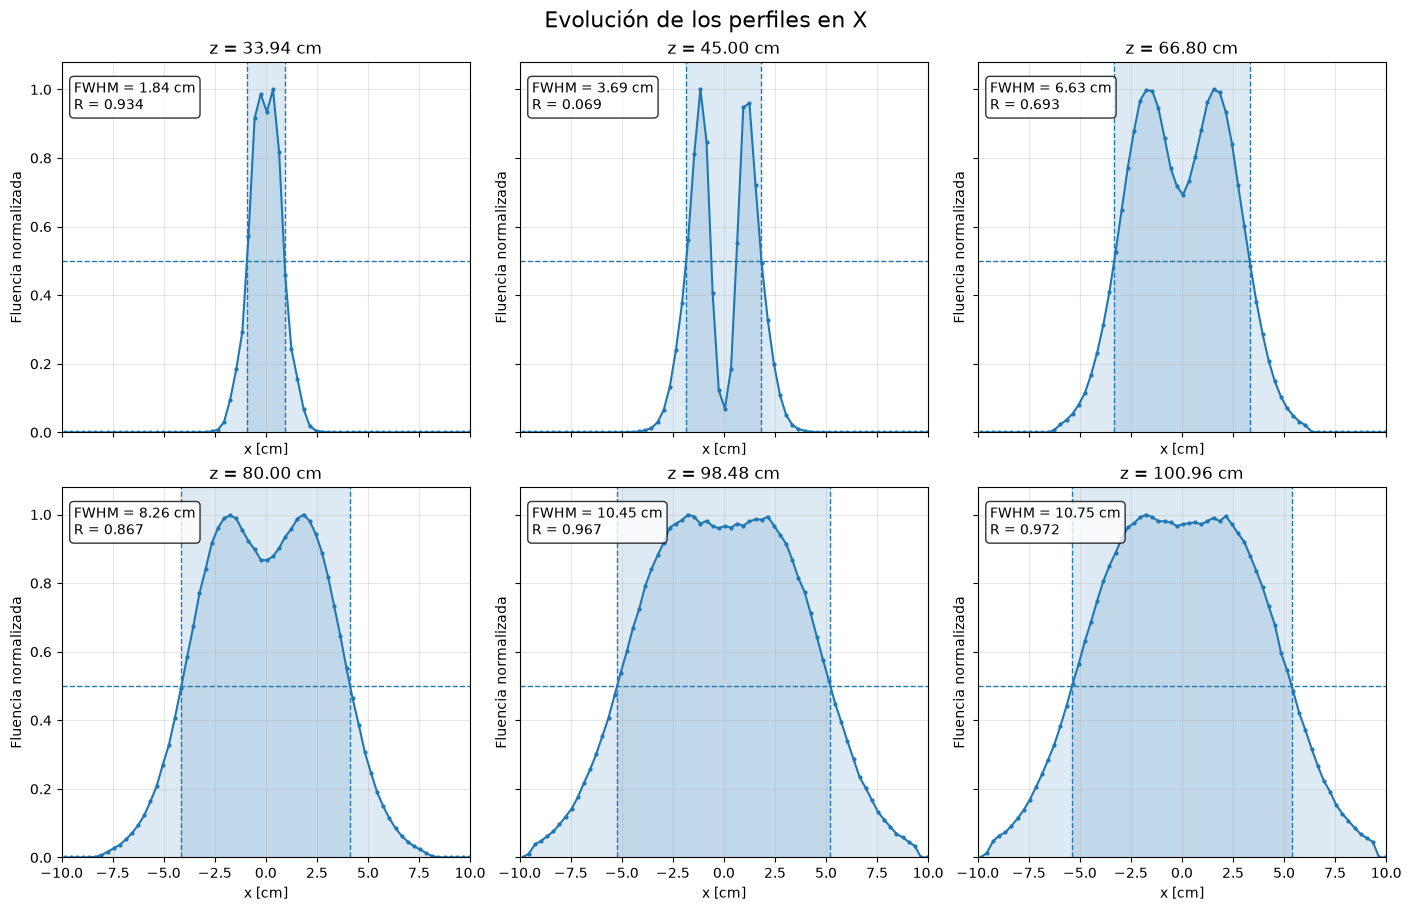

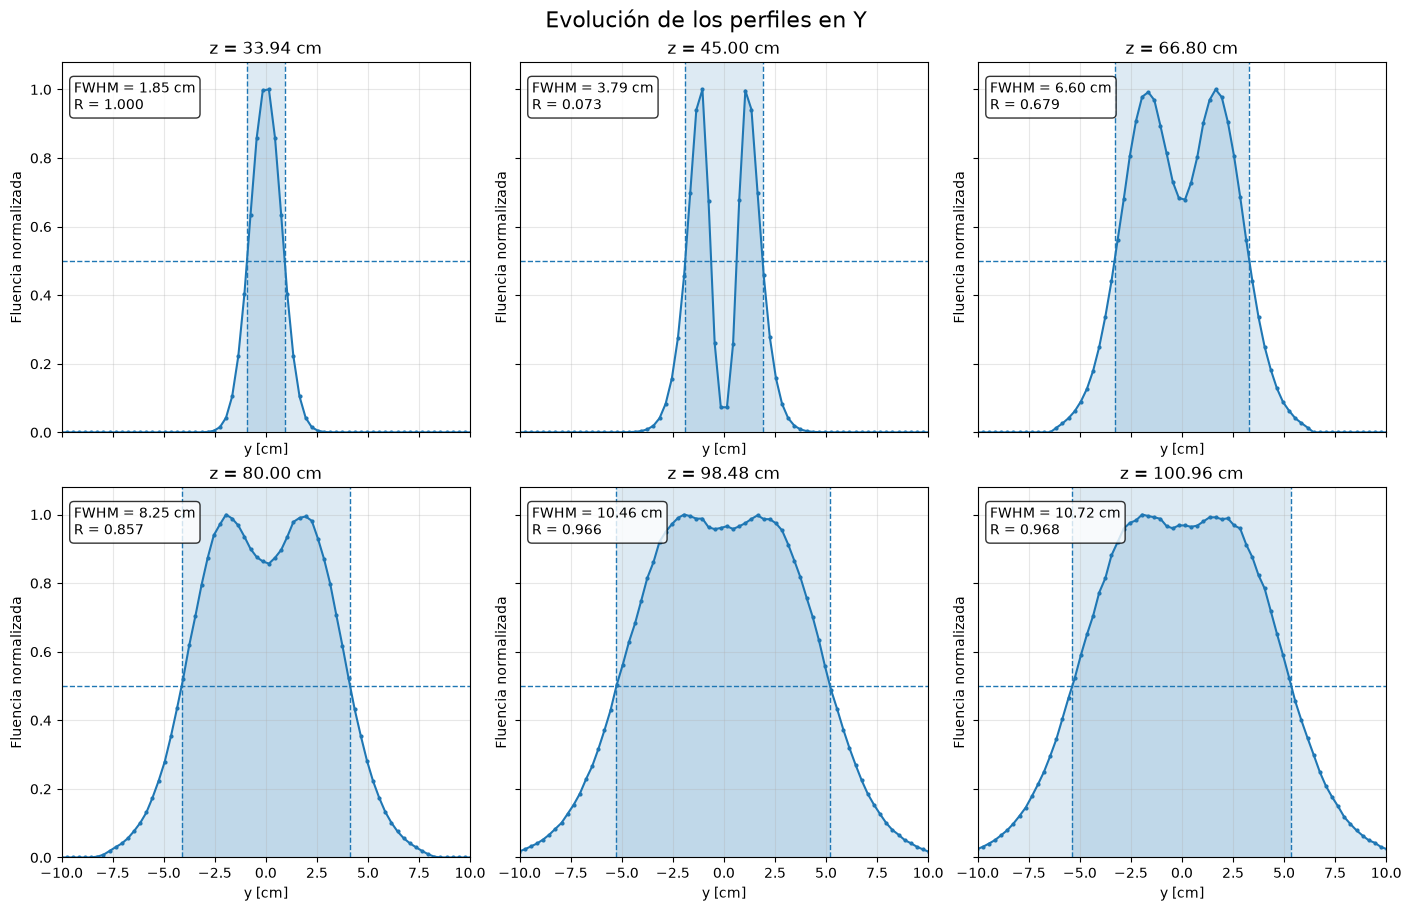

In [8]:
def graficar_mosaico_perfiles(resultados, eje="x"):
    fig, axes = plt.subplots(
        2, 3,
        figsize=(14, 9),
        sharex=True,
        sharey=True,
        constrained_layout=True
    )

    for ax, r in zip(axes.flat, resultados):
        if eje == "x":
            coord = r["x"]
            perfil = r["perfil_x"]
            fwhm = r["fwhm_x"]
            ratio = r["r_x"]
            etiqueta_x = "x [cm]"
            titulo = f"z = {r['z']:.2f} cm"
        else:
            coord = r["y"]
            perfil = r["perfil_y"]
            fwhm = r["fwhm_y"]
            ratio = r["r_y"]
            etiqueta_x = "y [cm]"
            titulo = f"z = {r['z']:.2f} cm"

        perfil_norm = perfil / np.max(perfil)
        mitad = 0.5

        indices = np.where(perfil_norm >= mitad)[0]

        if len(indices) >= 2:
            i_izq = indices[0]
            i_der = indices[-1]

            if i_izq > 0 and i_der < len(perfil_norm) - 1:
                x_izq = np.interp(
                    mitad,
                    perfil_norm[i_izq - 1:i_izq + 1],
                    coord[i_izq - 1:i_izq + 1]
                )

                x_der = np.interp(
                    mitad,
                    perfil_norm[i_der:i_der + 2][::-1],
                    coord[i_der:i_der + 2][::-1]
                )

                ax.axhline(mitad, linestyle="--", linewidth=1)
                ax.axvline(x_izq, linestyle="--", linewidth=1)
                ax.axvline(x_der, linestyle="--", linewidth=1)
                ax.axvspan(x_izq, x_der, alpha=0.15)

        ax.plot(coord, perfil_norm, marker="o", markersize=2)
        ax.fill_between(coord, perfil_norm, alpha=0.15)

        ax.set_title(titulo)
        ax.set_xlabel(etiqueta_x)
        ax.set_ylabel("Fluencia normalizada")
        ax.set_xlim(-10, 10)
        ax.set_ylim(0, 1.08)
        ax.grid(alpha=0.3)

        texto = (
            f"FWHM = {fwhm:.2f} cm\n"
            f"R = {ratio:.3f}"
        )

        ax.text(
            0.03, 0.95, texto,
            transform=ax.transAxes,
            va="top",
            ha="left",
            bbox=dict(boxstyle="round", facecolor="white", alpha=0.8)
        )

    if eje == "x":
        fig.suptitle("Evolución de los perfiles en X", fontsize=16)
    else:
        fig.suptitle("Evolución de los perfiles en Y", fontsize=16)

    plt.show()

graficar_mosaico_perfiles(resultados, eje="x")
graficar_mosaico_perfiles(resultados, eje="y")